# Práctica 7. Interferencia y paralelismo cuántico

## Información general

**Asignatura:** Computación cuántica  
**Sesión:** 7  
**Título:** Interferencia y paralelismo cuántico    
**Modalidad:** Individual  
**Entorno recomendado:** Jupyter Notebook  
**Bibliotecas:** NumPy, Matplotlib, Qiskit y Qiskit Aer

## Objetivos

En esta práctica vas a estudiar cómo las fases modifican los resultados de medida mediante interferencia.

Al finalizar la práctica deberás ser capaz de:

- Analizar circuitos sencillos usando amplitudes.
- Comparar circuitos que producen resultados deterministas y probabilísticos.
- Observar interferencia constructiva y destructiva.
- Comprobar cómo una fase puede convertirse en una diferencia de probabilidad.
- Diseñar circuitos que produzcan siempre 0, siempre 1 o una distribución equilibrada.
- Entender el paralelismo cuántico y sus limitaciones.
- Explicar por qué no pueden leerse todas las ramas de una superposición.

## Entrega

Entrega este notebook completado con código ejecutado, resultados visibles, tablas completadas, histogramas y respuestas razonadas.

## 1. Preparación del entorno

Ejecuta la siguiente celda para importar las bibliotecas necesarias.

In [1]:
# %pip install qiskit qiskit-aer matplotlib pylatexenc sympy

import matplotlib.pyplot as plt
import numpy as np

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

def applyStyle():
    plt.style.use("default")

    plt.rcParams["font.family"] = "serif"
    plt.rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif", "serif"]
    plt.rcParams["font.size"] = 12
    plt.rcParams["axes.labelsize"] = 12
    plt.rcParams["axes.titlesize"] = 12
    plt.rcParams["xtick.labelsize"] = 10
    plt.rcParams["ytick.labelsize"] = 10
    plt.rcParams["legend.fontsize"] = 10

    plt.rcParams["xtick.direction"] = "in"
    plt.rcParams["ytick.direction"] = "in"
    plt.rcParams["xtick.top"] = True
    plt.rcParams["ytick.right"] = True
    plt.rcParams["xtick.minor.visible"] = True
    plt.rcParams["ytick.minor.visible"] = True

    plt.rcParams["lines.linewidth"] = 1.0
    plt.rcParams["lines.markersize"] = 3

    plt.rcParams["legend.frameon"] = True
    plt.rcParams["legend.edgecolor"] = "black"
    plt.rcParams["legend.fancybox"] = False

COLOR_TARGET = "#5d54a4"
COLOR_PRED = "#9154a4"
COLOR_ERR = "#404040"

SEED = 42
np.set_printoptions(precision=5, suppress=True)

applyStyle()


def probsDict(state, decimals=5):
    return {str(k): round(float(v), decimals) for k, v in state.probabilities_dict().items()}

## 2. Parte A. Interferencia con NumPy

### Ejercicio 1. Definición de estados y puertas

Define con NumPy:

$$
|0\rangle =
\begin{pmatrix}
1 \\
0
\end{pmatrix}
\qquad
|1\rangle =
\begin{pmatrix}
0 \\
1
\end{pmatrix}
$$

$$
H =
\frac{1}{\sqrt{2}}
\begin{pmatrix}
1 & 1 \\
1 & -1
\end{pmatrix}
$$

$$
X =
\begin{pmatrix}
0 & 1 \\
1 & 0
\end{pmatrix}
\qquad
Y =
\begin{pmatrix}
0 & -i \\
i & 0
\end{pmatrix}
\qquad
Z =
\begin{pmatrix}
1 & 0 \\
0 & -1
\end{pmatrix}
$$

Muestra todas las matrices y comprueba sus dimensiones.

In [2]:
ket0 = np.array([1, 0], dtype=complex)
ket1 = np.array([0, 1], dtype=complex)

H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)

objects = {
    "|0>": ket0,
    "|1>": ket1,
    "H": H,
    "X": X,
    "Y": Y,
    "Z": Z,
}

for name, value in objects.items():
    print(f"{name} =")
    print(value)
    print(f"  shape = {value.shape}")
    print()

gates = {"H": H, "X": X, "Y": Y, "Z": Z}
print(f"all gates 2x2?     {all(g.shape == (2, 2) for g in gates.values())}")
print(f"all gates unitary? {all(np.allclose(g.conj().T @ g, np.eye(2)) for g in gates.values())}")

|0> =
[1.+0.j 0.+0.j]
  shape = (2,)

|1> =
[0.+0.j 1.+0.j]
  shape = (2,)

H =
[[ 0.70711+0.j  0.70711+0.j]
 [ 0.70711+0.j -0.70711+0.j]]
  shape = (2, 2)

X =
[[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]
  shape = (2, 2)

Y =
[[ 0.+0.j -0.-1.j]
 [ 0.+1.j  0.+0.j]]
  shape = (2, 2)

Z =
[[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]
  shape = (2, 2)

all gates 2x2?     True
all gates unitary? True


**Responde:**

1. ¿Qué dimensión tienen los estados?
2. ¿Qué dimensión tienen las puertas?
3. ¿Por qué estas puertas pueden actuar sobre un qubit?

**Respuesta:**

1. Dimensión 2.

2. Todas son 2 × 2.

3. Porque una matriz 2 × 2 lleva un vector de ℂ² a otro de ℂ². Además las cuatro son unitarias, así que conservan la norma y el resultado sigue siendo un estado válido.

### Ejercicio 2. Función de probabilidades

Implementa una función que devuelva las probabilidades de medir 0 y 1 en la base computacional.

In [3]:
def computeProbabilities(state, tolerance=1e-10):
    state = np.asarray(state, dtype=complex)

    if state.shape != (2,):
        raise ValueError("The state must have exactly two amplitudes")

    if not np.all(np.isfinite(state)):
        raise ValueError("The state contains non-finite values")

    if not np.isclose(np.linalg.norm(state), 1.0, atol=tolerance):
        raise ValueError("The state is not normalized")

    probs = np.abs(state) ** 2

    return {0: float(probs[0]), 1: float(probs[1])}


print(f"|0>: {computeProbabilities(ket0)}")
print(f"|1>: {computeProbabilities(ket1)}")
print(f"-|1>: {computeProbabilities(-ket1)}")
print()

invalidCases = {
    "notNormalized": ([1, 1], "norm sqrt(2) != 1"),
    "wrongDimension": ([1, 0, 0], "3 amplitudes"),
    "withNan": ([np.nan, 1], "NaN amplitude"),
}

for name, (vector, justification) in invalidCases.items():
    try:
        computeProbabilities(vector)
        outcome = "NOT DETECTED"
    except ValueError:
        outcome = "ValueError"
    print(f"{name:15s} -> {outcome:12s} | {justification}")

|0>: {0: 1.0, 1: 0.0}
|1>: {0: 0.0, 1: 1.0}
-|1>: {0: 0.0, 1: 1.0}

notNormalized   -> ValueError   | norm sqrt(2) != 1
wrongDimension  -> ValueError   | 3 amplitudes
withNan         -> ValueError   | NaN amplitude


**Responde:**

1. ¿Por qué se usa el módulo al cuadrado?
2. ¿Pueden las amplitudes ser negativas?
3. ¿Pueden las probabilidades ser negativas?

**Respuesta:**

1. Por la regla de Born: P(k) = |αₖ|². Las amplitudes son complejas, y el módulo al cuadrado es la forma de sacar de ellas un número real, no negativo y que sume 1 en total si el estado está normalizado.

2. Sí, e incluso complejas. Por ejemplo −|1⟩ tiene amplitud −1, y la función da `-|1>: {0: 0.0, 1: 1.0}`, lo mismo que |1⟩. El signo es justo lo que luego permite la interferencia.

3. No. |α|² ≥ 0 siempre.

## 3. Parte B. Circuitos $HH$ y $HZH$

### Ejercicio 3. Cálculo de $HH|0\rangle$

Calcula con NumPy:

$$
HH|0\rangle
$$

Muestra el estado final, sus probabilidades y desarrolla manualmente el cálculo de amplitudes.

In [4]:
stateAfterH = H @ ket0
stateHH = H @ stateAfterH

print(f"H|0>  = {stateAfterH}")
print(f"HH|0> = {stateHH}")
print(f"Probabilities: {computeProbabilities(stateHH)}")

H|0>  = [0.70711+0.j 0.70711+0.j]
HH|0> = [1.+0.j 0.+0.j]
Probabilities: {0: 0.9999999999999996, 1: 0.0}


Desarrollo manual:

$$
HH|0\rangle =
H(H|0\rangle)
=
H\left(\frac{|0\rangle + |1\rangle}{\sqrt{2}}\right)
=
\frac{1}{\sqrt{2}}\left(H|0\rangle + H|1\rangle\right)
=
\frac{1}{\sqrt{2}}\left(\frac{|0\rangle + |1\rangle}{\sqrt{2}} + \frac{|0\rangle - |1\rangle}{\sqrt{2}}\right)
=
\frac{1}{2}\left[(1 + 1)|0\rangle + (1 - 1)|1\rangle\right]
=
|0\rangle
$$

**Responde:**

1. ¿Qué estado final se obtiene?
2. ¿Qué resultado se obtendrá al medir?
3. ¿Qué amplitud se refuerza?
4. ¿Qué amplitud se cancela?

**Respuesta:**

1. |0⟩.

2. Siempre 0. La probabilidad sale `0.9999999999999996` por el redondeo de 1/√2, pero es 1.

3. La de |0⟩, las dos ramas aportan +½ y suman 1 (interferencia constructiva).

4. La de |1⟩, una rama aporta +½ y la otra −½, y se anulan (interferencia destructiva).

### Ejercicio 4. Cálculo de $HZH|0\rangle$

Calcula con NumPy:

$$
HZH|0\rangle
$$

Muestra el estado final, sus probabilidades y desarrolla manualmente el cálculo.

In [5]:
stateAfterZ = Z @ H @ ket0
stateHZH = H @ stateAfterZ

print(f"H|0>   = {H @ ket0}")
print(f"ZH|0>  = {stateAfterZ}   P = {computeProbabilities(stateAfterZ)}")
print(f"HZH|0> = {stateHZH}")
print(f"Probabilities: {computeProbabilities(stateHZH)}")

H|0>   = [0.70711+0.j 0.70711+0.j]
ZH|0>  = [ 0.70711+0.j -0.70711+0.j]   P = {0: 0.4999999999999999, 1: 0.4999999999999999}
HZH|0> = [0.+0.j 1.+0.j]
Probabilities: {0: 0.0, 1: 0.9999999999999996}


Desarrollo manual:

$$
HZH|0\rangle =
H(Z(H|0\rangle))
=
H\left(Z\,\frac{|0\rangle + |1\rangle}{\sqrt{2}}\right)
=
H\left(\frac{|0\rangle - |1\rangle}{\sqrt{2}}\right)
=
\frac{1}{\sqrt{2}}\left(\frac{|0\rangle + |1\rangle}{\sqrt{2}} - \frac{|0\rangle - |1\rangle}{\sqrt{2}}\right)
=
\frac{1}{2}\left[(1 - 1)|0\rangle + (1 + 1)|1\rangle\right]
=
|1\rangle
$$

**Responde:**

1. ¿Qué estado se obtiene después de la primera $H$?
2. ¿Qué efecto tiene $Z$ sobre ese estado?
3. ¿Qué estado final se obtiene?
4. ¿Qué resultado se obtendrá al medir?
5. ¿Qué ha cambiado respecto al circuito $HH$?

**Respuesta:**

1. |+⟩ = (|0⟩ + |1⟩)/√2.

2. Cambia el signo de la amplitud de |1⟩ y lo convierte en |−⟩. Las probabilidades no cambian.

3. |1⟩.

4. Siempre 1.

5. Solo el signo de la rama |1⟩ antes de la última H. Ese signo da la vuelta a la interferencia, ahora las contribuciones a |0⟩ se cancelan y las de |1⟩ se suman. El resultado pasa de siempre 0 a siempre 1.

### Ejercicio 5. Comparación de $HH$ y $HZH$

Completa la tabla:

| Circuito | Estado tras la primera H | Estado antes de medir | P(0) | P(1) | Resultado esperado |
|---|---|---|---:|---:|---|
| $$HH\|0\rangle$$ | \|+⟩ | \|0⟩ | 1 | 0 | Siempre 0 |
| $$HZH\|0\rangle$$ | \|+⟩ | \|1⟩ | 0 | 1 | Siempre 1 |

**Responde:**

1. ¿Por qué una puerta $Z$, que no cambia las probabilidades de $|+\rangle$, cambia el resultado final?
2. ¿Dónde aparece la interferencia constructiva en cada circuito?
3. ¿Dónde aparece la interferencia destructiva?
4. ¿Qué significa convertir fase en probabilidad?

**Respuesta:**

1. Porque sobre |+⟩ la Z es una fase relativa, no global, es decir lo convierte en |−⟩. Las probabilidades en la base Z no lo ven, pero la última H suma o resta las amplitudes según ese signo, y ahí sí se nota.

2. En HH sobre |0⟩ (+½ + ½ = 1). En HZH sobre |1⟩ (+½ + ½ = 1, después del signo de la Z).

3. En HH sobre |1⟩ (½ − ½ = 0). En HZH sobre |0⟩ (½ − ½ = 0).

4. Que una diferencia que no se ve al medir (ej: el signo entre |+⟩ y |−⟩, los dos 50/50) se transforma, con una puerta que hace interferir las amplitudes, en una diferencia en las probabilidades.

## 4. Parte C. Verificación con Qiskit

### Ejercicio 6. Circuito HH en Qiskit

Construye el circuito `HH` y obtén su vector de estado y probabilidades.

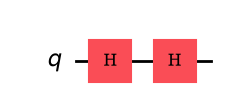

<IPython.core.display.Latex object>

vector        = [1.+0.j 0.+0.j]
probabilities = {'0': 1.0}
equal to HH|0> (NumPy)? True


In [6]:
qcHH = QuantumCircuit(1)
qcHH.h(0)
qcHH.h(0)

stateQcHH = Statevector.from_instruction(qcHH)

display(qcHH.draw("mpl"))
display(stateQcHH.draw("latex"))

print(f"vector        = {stateQcHH.data}")
print(f"probabilities = {probsDict(stateQcHH)}")
print(f"equal to HH|0> (NumPy)? {np.allclose(stateQcHH.data, stateHH)}")

**Responde:**

1. ¿Coincide con el cálculo hecho con NumPy?
2. ¿Por qué el resultado es determinista?
3. ¿Qué papel tiene la segunda Hadamard?

**Respuesta:**

1. Sí y el estado es |0⟩.

2. Porque el estado final es exactamente |0⟩, con P(0) = 1. Aunque a mitad del circuito el qubit está en |+⟩ (50/50), las dos ramas interfieren y la de |1⟩ desaparece.

3. Hace interferir las dos ramas que creó la primera. Como H² = I, deshace la superposición y devuelve el qubit a |0⟩.

### Ejercicio 7. Circuito HZH en Qiskit

Construye el circuito `HZH` y obtén su vector de estado y probabilidades.

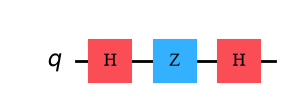

<IPython.core.display.Latex object>

vector        = [0.+0.j 1.+0.j]
probabilities = {'1': 1.0}
equal to HZH|0> (NumPy)? True


In [7]:
qcHZH = QuantumCircuit(1)
qcHZH.h(0)
qcHZH.z(0)
qcHZH.h(0)

stateQcHZH = Statevector.from_instruction(qcHZH)

display(qcHZH.draw("mpl"))
display(stateQcHZH.draw("latex"))

print(f"vector        = {stateQcHZH.data}")
print(f"probabilities = {probsDict(stateQcHZH)}")
print(f"equal to HZH|0> (NumPy)? {np.allclose(stateQcHZH.data, stateHZH)}")

**Responde:**

1. ¿Coincide con el cálculo hecho con NumPy?
2. ¿Qué papel tiene la puerta Z?
3. ¿Por qué este circuito produce siempre 1?

**Respuesta:**

1. Sí.

2. Cambia la fase relativa entre las dos ramas, de |+⟩ a |−⟩, sin tocar las probabilidades.

3. Porque la última H convierte |−⟩ en |1⟩, la amplitud de |0⟩ se cancela (½ − ½) y la de |1⟩ se refuerza. De hecho HZH = X, así que el circuito equivale a una NOT sobre |0⟩.

### Ejercicio 8. Medida de ambos circuitos

Añade medida a ambos circuitos y ejecútalos con `shots = 1000`.

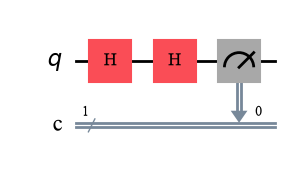

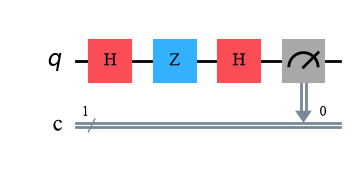

HH:  {'0': 1000}
HZH: {'1': 1000}
originals without measurements: True

notACircuit     -> TypeError    | not a QuantumCircuit
withMeasures    -> ValueError   | circuit already measured
zeroShots       -> ValueError   | shots = 0
floatShots      -> TypeError    | not an integer
boolShots       -> TypeError    | bool is not a number of shots


In [8]:
def runWithMeasurement(qcNoMeasure, shots=1000, seed=SEED):
    if not isinstance(qcNoMeasure, QuantumCircuit):
        raise TypeError("The circuit must be a QuantumCircuit")

    if qcNoMeasure.count_ops().get("measure", 0) > 0:
        raise ValueError("The circuit must not contain measurements")

    if isinstance(shots, bool) or not isinstance(shots, (int, np.integer)):
        raise TypeError("shots must be an integer")

    if shots <= 0:
        raise ValueError("shots must be positive")

    n = qcNoMeasure.num_qubits
    qc = QuantumCircuit(n, n)
    qc.compose(qcNoMeasure, inplace=True)
    qc.measure(range(n), range(n))

    simulator = AerSimulator(seed_simulator=seed)
    qcTranspiled = transpile(qc, simulator)
    result = simulator.run(qcTranspiled, shots=shots).result()
    return qc, result.get_counts()


shots = 1000

qcHHMeasured, countsHH = runWithMeasurement(qcHH, shots=shots)
qcHZHMeasured, countsHZH = runWithMeasurement(qcHZH, shots=shots)

display(qcHHMeasured.draw("mpl"))
display(qcHZHMeasured.draw("mpl"))

print(f"HH:  {countsHH}")
print(f"HZH: {countsHZH}")
print(f"originals without measurements: {qcHH.num_clbits == 0 and qcHZH.num_clbits == 0}")
print()

invalidCases = {
    "notACircuit": (("not a circuit", 100), "not a QuantumCircuit"),
    "withMeasures": ((qcHHMeasured, 100), "circuit already measured"),
    "zeroShots": ((qcHH, 0), "shots = 0"),
    "floatShots": ((qcHH, 10.5), "not an integer"),
    "boolShots": ((qcHH, True), "bool is not a number of shots"),
}

for name, ((circuit, n), justification) in invalidCases.items():
    try:
        runWithMeasurement(circuit, shots=n)
        outcome = "NOT DETECTED"
    except (TypeError, ValueError) as error:
        outcome = type(error).__name__
    print(f"{name:15s} -> {outcome:12s} | {justification}")

Completa la tabla:

| Circuito | Conteos esperados | Conteos obtenidos |
|---|---|---|
| $HH\|0\rangle$ | 100 % de 0 | {'0': 1000} |
| $HZH\|0\rangle$ | 100 % de 1 | {'1': 1000} |

**Responde:**

1. ¿Son exactamente deterministas los resultados?
2. ¿Por qué no aparece variabilidad estadística en estos dos casos ideales?
3. ¿Qué diferencia habría si el estado final fuese $|+\rangle$?

**Respuesta:**

1. Sí. Los 1000 shots dan 0 en HH y 1 en HZH.

2. Porque las probabilidades son exactamente 1 y 0. El simulador es ideal, sin ruido.

3. Saldría aproximadamente 50/50, con fluctuaciones de unos ±16 conteos (σ_f ≈ 0.016 con 1000 shots).


## 5. Parte D. Otras puertas entre Hadamard

### Ejercicio 9. Circuitos $HXH$, $HYH$, $HZH$

Construye y analiza los circuitos:

$$
HXH|0\rangle,\qquad HYH|0\rangle,\qquad HZH|0\rangle
$$

HXH


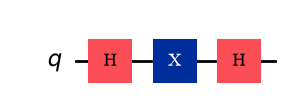

<IPython.core.display.Latex object>

  vector        = [1.+0.j 0.+0.j]
  probabilities = {'0': 1.0}
  counts        = {'0': 1000}

HYH


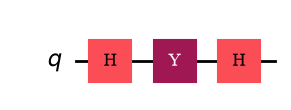

<IPython.core.display.Latex object>

  vector        = [0.+0.j 0.-1.j]
  probabilities = {'1': 1.0}
  counts        = {'1': 1000}

HZH


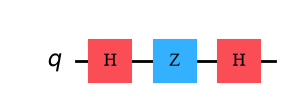

<IPython.core.display.Latex object>

  vector        = [0.+0.j 1.+0.j]
  probabilities = {'1': 1.0}
  counts        = {'1': 1000}

HYH|0> = -i|1>? True


In [9]:
def hadamardSandwich(gateName):
    if gateName not in ("id", "x", "y", "z", "s", "t"):
        raise ValueError(f"Unknown gate: {gateName!r}")

    qc = QuantumCircuit(1)
    qc.h(0)

    getattr(qc, gateName)(0)

    qc.h(0)
    return qc


sandwichCircuits = {
    "HXH": hadamardSandwich("x"),
    "HYH": hadamardSandwich("y"),
    "HZH": hadamardSandwich("z"),
}

sandwichResults = {}

for name, qc in sandwichCircuits.items():
    print(name)
    state = Statevector.from_instruction(qc)
    probs = probsDict(state)
    qcMeasured, counts = runWithMeasurement(qc, shots=1000)

    sandwichResults[name] = {
        "state": state,
        "probs": probs,
        "counts": counts,
    }

    display(qc.draw("mpl"))
    display(state.draw("latex"))
    print(f"  vector        = {state.data}")
    print(f"  probabilities = {probs}")
    print(f"  counts        = {counts}")
    print()

print(f"HYH|0> = -i|1>? {np.allclose(sandwichResults['HYH']['state'].data, -1j * ket1)}")

Completa la tabla:

| Circuito | Estado final | P(0) | P(1) | Resultado dominante |
|---|---|---:|---:|---|
| $HXH\|0\rangle$ | \|0⟩ | 1 | 0 | 0 (1000 de 1000) |
| $HYH\|0\rangle$ | −i\|1⟩ | 0 | 1 | 1 (1000 de 1000) |
| $HZH\|0\rangle$ | \|1⟩ | 0 | 1 | 1 (1000 de 1000) |

**Responde:**

1. ¿Qué circuito produce siempre 0?
2. ¿Qué circuitos producen siempre 1?
3. ¿Aparecen fases globales en alguno de los resultados?
4. ¿Se pueden detectar las fases globales midiendo en la base computacional?
5. ¿Qué relación se observa entre $HZH$ y $X$?

**Respuesta:**

1. HXH. Sobre |+⟩ la X no hace nada, así que es como HH.

2. HYH y HZH.

3. Sí, en HYH el estado final es −i|1⟩. El −i es una fase global, porque multiplica a todo el estado.

4. No. |−i|² = 1, así que −i|1⟩ y |1⟩ dan las mismas probabilidades. Y como la fase global no cambia ninguna probabilidad en ninguna base, no se puede detectar con ninguna medida: son el mismo estado físico.

5. HZH|0⟩ = |1⟩ = X|0⟩, y de hecho HZH = X como matrices.

### Ejercicio 10. Comprobación matricial de $HZH = X$

Calcula con NumPy:

$$
HZH
$$

y compáralo con:

$$
X
$$

In [10]:
HZH = H @ Z @ H
HXH = H @ X @ H
HYH = H @ Y @ H

print("HZH =")
print(HZH)
print("X =")
print(X)
print(f"HZH = X? {np.allclose(HZH, X)}   (exact ==: {np.array_equal(HZH, X)}, max diff = {np.max(np.abs(HZH - X)):.2e})")

print()
print("HXH =")
print(HXH)
print("Z =")
print(Z)
print(f"HXH = Z? {np.allclose(HXH, Z)}   (exact ==: {np.array_equal(HXH, Z)}, max diff = {np.max(np.abs(HXH - Z)):.2e})")

print()
print(f"HYH = -Y? {np.allclose(HYH, -Y)}")

HZH =
[[-0.+0.j  1.+0.j]
 [ 1.+0.j -0.+0.j]]
X =
[[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]
HZH = X? True   (exact ==: False, max diff = 2.22e-16)

HXH =
[[ 1.+0.j -0.+0.j]
 [ 0.+0.j -1.+0.j]]
Z =
[[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]
HXH = Z? True   (exact ==: False, max diff = 2.22e-16)

HYH = -Y? True


**Responde:**

1. ¿Se cumple exactamente $HZH=X$?
2. ¿Qué significa esta igualdad a nivel de circuitos?
3. ¿Por qué Hadamard puede interpretarse como un cambio de base?
4. ¿Qué ocurre con $HXH$?

**Respuesta:**

1. Matemáticamente sí. Numéricamente no del todo.

2. Que el bloque H–Z–H se puede sustituir por una X en cualquier circuito sin cambiar nada, y al revés. Sirve para simplificar circuitos o para construir una puerta a partir de otras.

3. Porque H lleva la base Z a la base X (|0⟩ ↔ |+⟩, |1⟩ ↔ |−⟩). HZH es igual a pasar a la base X, aplicar Z y volver. Una Z en la base X actúa como una X en la base Z.

4. HXH = Z. Es la relación simétrica, H intercambia X y Z. Con Y sale HYH = −Y, que solo se diferencia de Y en el signo.

## 6. Parte E. Diseñar circuitos

### Ejercicio 11. Circuito que produzca siempre 0

Diseña al menos dos circuitos distintos que, partiendo de $|0\rangle$, produzcan siempre 0 al medir.

Circuit 0A


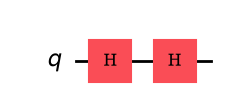

<IPython.core.display.Latex object>

  vector        = [1.+0.j 0.+0.j]
  probabilities = {'0': 1.0}
  equivalent to |0> (|<0|psi>| = 1)? True

Circuit 0B


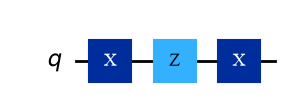

<IPython.core.display.Latex object>

  vector        = [-1.+0.j  0.+0.j]
  probabilities = {'0': 1.0}
  equivalent to |0> (|<0|psi>| = 1)? True



In [11]:
alwaysZeroCircuits = []

qc0A = QuantumCircuit(1)
qc0A.h(0)
qc0A.h(0)
alwaysZeroCircuits.append(("Circuit 0A", qc0A))

qc0B = QuantumCircuit(1)
qc0B.x(0)
qc0B.z(0)
qc0B.x(0)
alwaysZeroCircuits.append(("Circuit 0B", qc0B))

for name, qc in alwaysZeroCircuits:
    print(name)
    state = Statevector.from_instruction(qc)
    display(qc.draw("mpl"))
    display(state.draw("latex"))
    print(f"  vector        = {state.data}")
    print(f"  probabilities = {probsDict(state)}")
    print(f"  equivalent to |0> (|<0|psi>| = 1)? {np.isclose(abs(np.vdot(ket0, state.data)), 1.0)}")
    print()

**Responde:**

1. ¿Qué tienen en común los estados finales?
2. ¿Puede haber fases globales y seguir midiendo siempre 0?

**Respuesta:**

1. Los dos son |0⟩ salvo una fase global: el circuito 0A da |0⟩ y el 0B (XZX) da −|0⟩. En los dos casos |⟨0|ψ⟩| = 1, así que P(0) = 1.

2. Sí. El circuito 0B termina en −|0⟩ y sigue dando P(0) = 1, porque |−1|² = 1. La fase global no cambia ninguna probabilidad.

### Ejercicio 12. Circuito que produzca siempre 1

Diseña al menos dos circuitos distintos que, partiendo de $|0\rangle$, produzcan siempre 1 al medir.

Circuit 1A


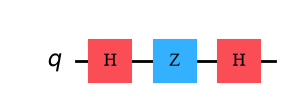

<IPython.core.display.Latex object>

  vector        = [0.+0.j 1.+0.j]
  probabilities = {'1': 1.0}
  equivalent to |1> (|<1|psi>| = 1)? True

Circuit 1B


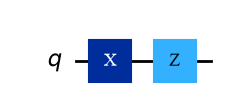

<IPython.core.display.Latex object>

  vector        = [ 0.+0.j -1.+0.j]
  probabilities = {'1': 1.0}
  equivalent to |1> (|<1|psi>| = 1)? True

Circuit 1C


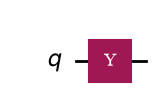

<IPython.core.display.Latex object>

  vector        = [0.+0.j 0.+1.j]
  probabilities = {'1': 1.0}
  equivalent to |1> (|<1|psi>| = 1)? True



In [12]:
alwaysOneCircuits = []

qc1A = QuantumCircuit(1)
qc1A.h(0)
qc1A.z(0)
qc1A.h(0)
alwaysOneCircuits.append(("Circuit 1A", qc1A))

qc1B = QuantumCircuit(1)
qc1B.x(0)
qc1B.z(0)
alwaysOneCircuits.append(("Circuit 1B", qc1B))

qc1C = QuantumCircuit(1)
qc1C.y(0)
alwaysOneCircuits.append(("Circuit 1C", qc1C))

for name, qc in alwaysOneCircuits:
    print(name)
    state = Statevector.from_instruction(qc)
    display(qc.draw("mpl"))
    display(state.draw("latex"))
    print(f"  vector        = {state.data}")
    print(f"  probabilities = {probsDict(state)}")
    print(f"  equivalent to |1> (|<1|psi>| = 1)? {np.isclose(abs(np.vdot(ket1, state.data)), 1.0)}")
    print()

**Responde:**

1. ¿Qué estado final deben producir estos circuitos?
2. ¿Importa que el estado final sea $-|1\rangle$ o $i|1\rangle$?
3. ¿Por qué?

**Respuesta:**

1. |1⟩ salvo fase global. He puesto tres circuitos, HZH da |1⟩, ZX da −|1⟩ e Y da i|1⟩.

2. No. Los tres dan P(1) = 1.

3. Porque −1 e i multiplican a todo el estado, son fases globales y |−1|² = |i|² = 1.

### Ejercicio 13. Circuito con distribución equilibrada

Diseña al menos dos circuitos que produzcan:

$$
P(0)=P(1)=\frac{1}{2}
$$

Balanced A


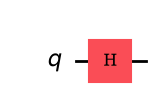

<IPython.core.display.Latex object>

  vector        = [0.70711+0.j 0.70711+0.j]
  probabilities = {'0': 0.5, '1': 0.5}
  counts        = {'1': 486, '0': 514}


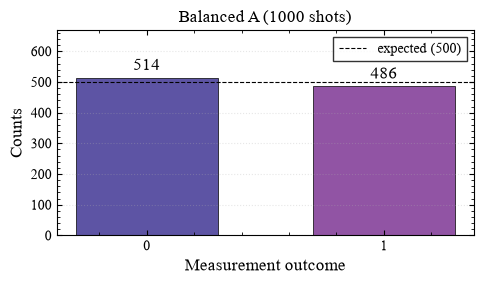

Balanced B


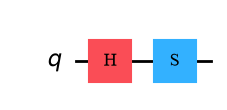

<IPython.core.display.Latex object>

  vector        = [0.70711+0.j      0.     +0.70711j]
  probabilities = {'0': 0.5, '1': 0.5}
  counts        = {'1': 486, '0': 514}


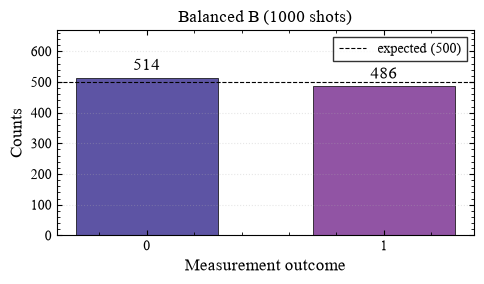

same probabilities? True
same state?         False
|<A|B>|             = 0.70711


In [13]:
balancedCircuits = []

qceA = QuantumCircuit(1)
qceA.h(0)
balancedCircuits.append(("Balanced A", qceA))

qceB = QuantumCircuit(1)
qceB.h(0)
qceB.s(0)
balancedCircuits.append(("Balanced B", qceB))

balancedStates = {}

for name, qc in balancedCircuits:
    print(name)
    state = Statevector.from_instruction(qc)
    qcMeasured, counts = runWithMeasurement(qc, shots=1000)
    balancedStates[name] = state

    display(qc.draw("mpl"))
    display(state.draw("latex"))
    print(f"  vector        = {state.data}")
    print(f"  probabilities = {probsDict(state)}")
    print(f"  counts        = {counts}")

    labels = sorted(counts)
    values = [counts[k] for k in labels]

    fig, ax = plt.subplots(figsize=(5, 3))
    bars = ax.bar(labels, values, color=[COLOR_TARGET, COLOR_PRED], width=0.6, edgecolor="black", linewidth=0.5)
    ax.axhline(500, color="black", linestyle="--", linewidth=0.8, label="expected (500)")
    ax.bar_label(bars, padding=3)
    ax.set_title(f"{name} (1000 shots)")
    ax.set_xlabel("Measurement outcome")
    ax.set_ylabel("Counts")
    ax.set_ylim(0, max(values) * 1.3)
    ax.legend(loc="upper right")
    ax.grid(True, axis="y", linestyle=":", alpha=0.3)
    plt.tight_layout()
    plt.show()

stA, stB = balancedStates["Balanced A"], balancedStates["Balanced B"]
print(f"same probabilities? {np.allclose(stA.probabilities(), stB.probabilities())}")
print(f"same state?         {stA.equiv(stB)}")
print(f"|<A|B>|             = {abs(np.vdot(stA.data, stB.data)):.5f}")

**Responde:**

1. ¿Los conteos son exactamente 50 % y 50 %?
2. ¿Qué diferencia hay entre probabilidad teórica y frecuencia observada?
3. ¿Pueden dos estados distintos producir la misma distribución equilibrada?

**Respuesta:**

1. No, salen 514 y 486. La desviación es 0.014, menor que σ_f = √(0.25/1000) ≈ 0.016, así que es normal.

2. La probabilidad es exacta y sale de las amplitudes (0.5). La frecuencia es lo que se mide en un número finito de shots (0.514) y solo se acerca a la probabilidad al aumentar los shots.

3. Sí. El A es |+⟩ y el B es |+i⟩ = (|0⟩ + i|1⟩)/√2, tienen las mismas probabilidades pero no son el mismo estado. Se diferencian en la fase relativa (0° frente a 90°).

## 7. Parte F. Fase y probabilidad

### Ejercicio 14. Estados con la misma distribución

Considera:

$$
|+\rangle =
\frac{|0\rangle + |1\rangle}{\sqrt{2}}
$$

$$
|-\rangle =
\frac{|0\rangle - |1\rangle}{\sqrt{2}}
$$

$$
|+i\rangle =
\frac{|0\rangle + i|1\rangle}{\sqrt{2}}
$$

Define los tres estados con NumPy y calcula sus probabilidades.

In [14]:
ketPlus = (ket0 + ket1) / np.sqrt(2)
ketMinus = (ket0 - ket1) / np.sqrt(2)
ketPlusI = (ket0 + 1j * ket1) / np.sqrt(2)

phaseStates = {
    "|+>": ketPlus,
    "|->": ketMinus,
    "|+i>": ketPlusI,
}

print(f"{'state':>5} | {'amp |0>':>15} | {'amp |1>':>15} | {'P(0)':>5} {'P(1)':>5} | {'rel. phase':>10}")
print("-" * 70)
for name, state in phaseStates.items():
    p = computeProbabilities(state)
    relativePhase = np.degrees(np.angle(state[1]) - np.angle(state[0]))
    print(f"{name:>5} | {state[0]:>15.4f} | {state[1]:>15.4f} | {p[0]:>5.2f} {p[1]:>5.2f} | {relativePhase:>8.1f} °")

print()
print("After H:")
for name, state in phaseStates.items():
    p = computeProbabilities(H @ state)
    print(f"  H{name:<5} -> P(0) = {p[0]:.2f}, P(1) = {p[1]:.2f}")

state |         amp |0> |         amp |1> |  P(0)  P(1) | rel. phase
----------------------------------------------------------------------
  |+> |  0.7071+0.0000j |  0.7071+0.0000j |  0.50  0.50 |      0.0 °
  |-> |  0.7071+0.0000j | -0.7071+0.0000j |  0.50  0.50 |    180.0 °
 |+i> |  0.7071+0.0000j |  0.0000+0.7071j |  0.50  0.50 |     90.0 °

After H:
  H|+>   -> P(0) = 1.00, P(1) = 0.00
  H|->   -> P(0) = 0.00, P(1) = 1.00
  H|+i>  -> P(0) = 0.50, P(1) = 0.50


Completa:

| Estado | Amplitud de $\|0\rangle$ | Amplitud de $\|1\rangle$ | P(0) | P(1) |
|---|---|---|---:|---:|
| $\|+\rangle$ | 1/√2 | 1/√2 | 0.5 | 0.5 |
| $\|-\rangle$ | 1/√2 | −1/√2 | 0.5 | 0.5 |
| $\|+i\rangle$ | 1/√2 | i/√2 | 0.5 | 0.5 |

**Responde:**

1. ¿Tienen la misma distribución de medida en la base computacional?
2. ¿Son el mismo estado?
3. ¿Qué información no aparece en las probabilidades?
4. ¿Qué operación puede transformar diferencias de fase en diferencias de probabilidad?

**Respuesta:**

1. Sí, los tres dan 0.5 y 0.5.

2. No. Se diferencian en la fase relativa de |1⟩, 0°, 180° y 90°.

3. La fase relativa entre las amplitudes. La probabilidad solo usa el módulo, y los tres tienen módulo 1/√2 en las dos componentes.

4. Una puerta que haga interferir las amplitudes antes de medir, como H. Después de H, |+⟩ da siempre 0, |−⟩ siempre 1 y |+i⟩ sigue en 50/50. Para distinguir |+i⟩ habría que medir en la base Y, ej: aplicando S† y luego H.

### Ejercicio 15. Distinguir $|+\rangle$ y $|-\rangle$

Diseña un procedimiento para distinguir $|+\rangle$ y $|-\rangle$. Pista: antes de medir, aplica una puerta Hadamard.

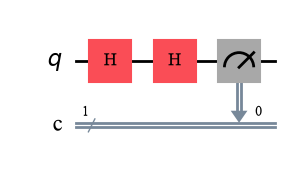

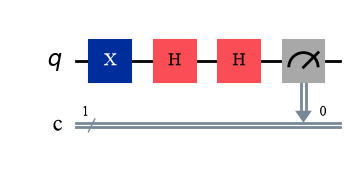

|+> + H: {'0': 1000}
|-> + H: {'1': 1000}

|+> direct: {'1': 486, '0': 514}
|-> direct: {'1': 486, '0': 514}


In [15]:
qcPlus = QuantumCircuit(1)
qcPlus.h(0)
qcPlus.h(0)

qcMinus = QuantumCircuit(1)
qcMinus.x(0)
qcMinus.h(0)
qcMinus.h(0)

qcPlusMeasured, countsPlus = runWithMeasurement(qcPlus, shots=1000)
qcMinusMeasured, countsMinus = runWithMeasurement(qcMinus, shots=1000)

display(qcPlusMeasured.draw("mpl"))
display(qcMinusMeasured.draw("mpl"))

print(f"|+> + H: {countsPlus}")
print(f"|-> + H: {countsMinus}")
print()

qcPlusDirect = QuantumCircuit(1)
qcPlusDirect.h(0)
qcMinusDirect = QuantumCircuit(1)
qcMinusDirect.x(0)
qcMinusDirect.h(0)

print(f"|+> direct: {runWithMeasurement(qcPlusDirect)[1]}")
print(f"|-> direct: {runWithMeasurement(qcMinusDirect)[1]}")

Completa la tabla:

| Estado preparado | Operación antes de medir | Resultado esperado |
|---|---|---|
| $\|+\rangle$ | H | Siempre 0 (obtenido {'0': 1000}) |
| $\|-\rangle$ | H | Siempre 1 (obtenido {'1': 1000}) |

**Responde:**

1. ¿Por qué medir directamente no permite distinguirlos de forma determinista?
2. ¿Por qué aplicar $H$ antes de medir sí permite distinguirlos?
3. ¿Qué demuestra este ejercicio sobre la fase relativa?

**Respuesta:**

1. Porque en la base Z los dos tienen P(0) = P(1) = 0.5, cada shot da 0 o 1 al azar y ningún resultado dice de qué estado venía.

2. Porque H|+⟩ = |0⟩ y H|−⟩ = |1⟩, pasa la base X a la base Z. Con un solo shot ya se sabe qué estado era.

3. Que la fase relativa es información física real. No se ve en una medida directa, pero cambia el resultado en cuanto se hace interferir con una puerta.

## 8. Parte G. Paralelismo cuántico

### Ejercicio 16. Superposición de varios qubits

Construye un circuito de tres qubits con Hadamard en todos ellos.

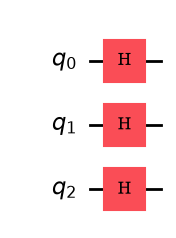

<IPython.core.display.Latex object>

{'000': 0.125, '001': 0.125, '010': 0.125, '011': 0.125, '100': 0.125, '101': 0.125, '110': 0.125, '111': 0.125}
States with non-zero probability: 8
all equal to 1/8?                 True


In [16]:
qc3 = QuantumCircuit(3)
for qubit in range(3):
    qc3.h(qubit)

state3 = Statevector.from_instruction(qc3)
probs3 = probsDict(state3)

display(qc3.draw("mpl"))
display(state3.draw("latex"))
print(probs3)
print(f"States with non-zero probability: {len(probs3)}")
print(f"all equal to 1/8?                 {all(np.isclose(p, 1 / 8) for p in probs3.values())}")

**Responde:**

1. ¿Cuántas ramas aparecen en la superposición?
2. ¿Qué probabilidad tiene cada rama?
3. ¿Qué ocurre si medimos el circuito?
4. ¿Obtenemos todas las ramas o solo una?

**Respuesta:**

1. Ocho, de |000⟩ a |111⟩, es decir 2³.

2. 1/8 = 0.125 cada una, con amplitud √2/4 = 1/√8.

3. El estado colapsa a una sola de las ocho cadenas, elegida al azar con probabilidad 1/8, y la superposición desaparece.

4. Solo una por ejecución, con un solo shot sale una única cadena.

### Ejercicio 17. Medida de una superposición de tres qubits

Añade tres bits clásicos, mide los tres qubits y ejecuta con `shots = 1000`. Representa los resultados en un histograma.

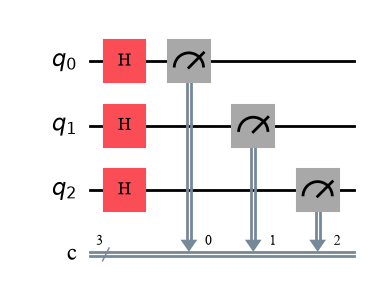

{'001': 137, '110': 115, '100': 123, '101': 127, '111': 134, '011': 121, '010': 136, '000': 107}
1 shot -> {'111': 1}

outcome |    N |      f | |f - 1/8| | in 2 sigma
-------------------------------------------------
    000 |  107 |  0.107 |    0.0180 |       True
    001 |  137 |  0.137 |    0.0120 |       True
    010 |  136 |  0.136 |    0.0110 |       True
    011 |  121 |  0.121 |    0.0040 |       True
    100 |  123 |  0.123 |    0.0020 |       True
    101 |  127 |  0.127 |    0.0020 |       True
    110 |  115 |  0.115 |    0.0100 |       True
    111 |  134 |  0.134 |    0.0090 |       True


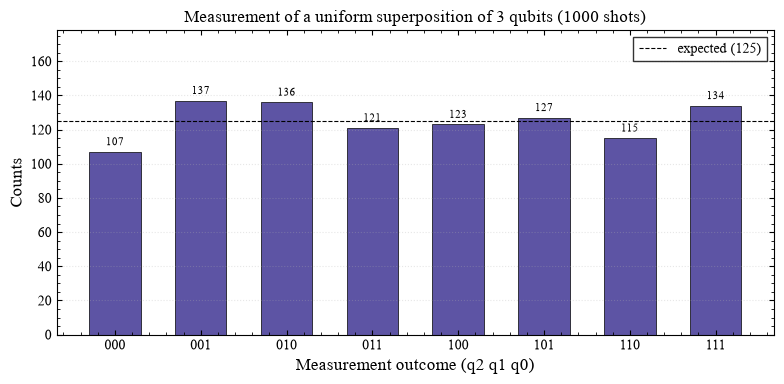

In [17]:
qc3Measure = QuantumCircuit(3, 3)
for qubit in range(3):
    qc3Measure.h(qubit)
qc3Measure.measure(range(3), range(3))  # qi -> ci

simulator = AerSimulator(seed_simulator=SEED)
qcTranspiled = transpile(qc3Measure, simulator)
result = simulator.run(qcTranspiled, shots=1000).result()
counts3 = result.get_counts()

display(qc3Measure.draw("mpl"))
print(counts3)

singleShot = AerSimulator(seed_simulator=SEED).run(qcTranspiled, shots=1).result().get_counts()
print(f"1 shot -> {singleShot}")
print()

sigma3 = np.sqrt((1 / 8) * (7 / 8) / 1000)
print(f"{'outcome':>7} | {'N':>4} | {'f':>6} | {'|f - 1/8|':>9} | {'in 2 sigma':>10}")
print("-" * 49)
for outcome in [format(k, "03b") for k in range(8)]:
    f = counts3.get(outcome, 0) / 1000
    print(f"{outcome:>7} | {counts3.get(outcome, 0):>4} | {f:>6.3f} | {abs(f - 1 / 8):>9.4f} | {str(abs(f - 1 / 8) < 2 * sigma3):>10}")

labels = [format(k, "03b") for k in range(8)]
values = [counts3.get(k, 0) for k in labels]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels, values, color=COLOR_TARGET, width=0.6, edgecolor="black", linewidth=0.5)
ax.axhline(125, color="black", linestyle="--", linewidth=0.8, label="expected (125)")
ax.bar_label(bars, padding=3, fontsize=8)
ax.set_title("Measurement of a uniform superposition of 3 qubits (1000 shots)")
ax.set_xlabel("Measurement outcome (q2 q1 q0)")
ax.set_ylabel("Counts")
ax.set_ylim(0, max(values) * 1.3)
ax.legend(loc="upper right")
ax.grid(True, axis="y", linestyle=":", alpha=0.3)
plt.tight_layout()
plt.show()

**Responde:**

1. ¿Aparecen todos los estados posibles?
2. ¿Aparecen todos el mismo número exacto de veces?
3. ¿Qué se espera teóricamente?
4. ¿Por qué esto no significa que podamos leer todas las ramas de la superposición en una sola ejecución?

**Respuesta:**

1. Sí, salen las 8 cadenas.

2. No. Van de 107 (000) a 137 (001).

3. 1000/8 = 125 cada una. Con σ_f = √((1/8)(7/8)/1000) ≈ 0.0105, unos 10 conteos, todas están dentro de 2σ.

4. Porque el histograma junta 1000 ejecuciones distintas, y cada una da una sola cadena. Aun así solo obtenemos probabilidades, no las amplitudes. El paralelismo cuántico solo sirve si se usa interferencia para concentrar la probabilidad en la respuesta útil.

### Ejercicio 18. Evaluación simultánea de una operación

Considera la puerta $X$, que transforma:

$$
|0\rangle \rightarrow |1\rangle
\qquad
|1\rangle \rightarrow |0\rangle
$$

Prepara el estado:

$$
|+\rangle =
\frac{|0\rangle + |1\rangle}{\sqrt{2}}
$$

y aplica $X$. Calcula:

$$
X|+\rangle
$$

X|0>  = [0.+0.j 1.+0.j]
X|1>  = [1.+0.j 0.+0.j]
X|+>  = [0.70711+0.j 0.70711+0.j]
(X|0> + X|1>)/sqrt(2) = [0.70711+0.j 0.70711+0.j]   (linearity)
Probabilities: {0: 0.4999999999999999, 1: 0.4999999999999999}
X|+> = |+>? True



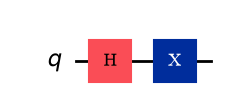

<IPython.core.display.Latex object>

probabilities = {'0': 0.5, '1': 0.5}
equal to X|+> (NumPy)? True


In [18]:
stateXPlus = X @ ketPlus

print(f"X|0>  = {X @ ket0}")
print(f"X|1>  = {X @ ket1}")
print(f"X|+>  = {stateXPlus}")
print(f"(X|0> + X|1>)/sqrt(2) = {(X @ ket0 + X @ ket1) / np.sqrt(2)}   (linearity)")
print(f"Probabilities: {computeProbabilities(stateXPlus)}")
print(f"X|+> = |+>? {np.allclose(stateXPlus, ketPlus)}")
print()

qcXPlus = QuantumCircuit(1)
qcXPlus.h(0)
qcXPlus.x(0)

stateQcXPlus = Statevector.from_instruction(qcXPlus)
display(qcXPlus.draw("mpl"))
display(stateQcXPlus.draw("latex"))
print(f"probabilities = {probsDict(stateQcXPlus)}")
print(f"equal to X|+> (NumPy)? {np.allclose(stateQcXPlus.data, stateXPlus)}")

**Responde:**

1. ¿Qué efecto tiene $X$ sobre cada componente de la superposición?
2. ¿Qué estado final se obtiene?
3. ¿Ha cambiado la distribución de probabilidad?
4. ¿Por qué este ejemplo ilustra la linealidad de las operaciones cuánticas?

**Respuesta:**

1. Actúa sobre las dos a la vez, |0⟩ → |1⟩ y |1⟩ → |0⟩.

2. X|+⟩ = (|1⟩ + |0⟩)/√2 = |+⟩. El estado no cambia, porque |+⟩ es autoestado de X con autovalor +1.

3. No, sigue en 0.5 y 0.5.

4. Porque X|+⟩ = (X|0⟩ + X|1⟩)/√2, aplicar la puerta a la superposición es aplicarla a cada rama y sumar. Con una sola aplicación de X se han evaluado las dos entradas, que es la idea del paralelismo cuántico, aunque al medir no se nota nada.

## 9. Reto avanzado

### Ejercicio 19. Diseñar un circuito con interferencia controlada

Diseña tres circuitos de un qubit que partan de $|0\rangle$ y produzcan:

1. Resultado siempre 0.
2. Resultado siempre 1.
3. Distribución equilibrada.

Condiciones:

- Al menos uno debe usar una puerta $Z$.
- Al menos uno debe usar dos puertas Hadamard.
- Al menos uno debe usar una fase que no sea visible directamente en una medida intermedia.

Para cada circuito:

- Dibuja el circuito.
- Obtén el estado final.
- Obtén las probabilidades.
- Ejecuta 1000 shots.
- Explica el resultado usando amplitudes e interferencia.

Always 0


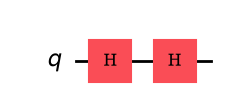

<IPython.core.display.Latex object>

  before last H = [0.70711+0.j 0.70711+0.j]   P = {'0': 0.5, '1': 0.5}
  final vector  = [1.+0.j 0.+0.j]
  probabilities = {'0': 1.0}
  counts        = {'0': 1000}

Always 1


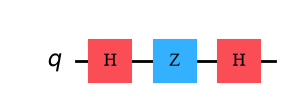

<IPython.core.display.Latex object>

  before last H = [ 0.70711+0.j -0.70711+0.j]   P = {'0': 0.5, '1': 0.5}
  final vector  = [0.+0.j 1.+0.j]
  probabilities = {'1': 1.0}
  counts        = {'1': 1000}

Balanced


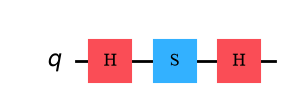

<IPython.core.display.Latex object>

  before last H = [0.70711+0.j      0.     +0.70711j]   P = {'0': 0.5, '1': 0.5}
  final vector  = [0.5+0.5j 0.5-0.5j]
  probabilities = {'0': 0.5, '1': 0.5}
  counts        = {'1': 486, '0': 514}



In [19]:
challengeCircuits = []

qcChallenge0 = QuantumCircuit(1)
qcChallenge0.h(0)
qcChallenge0.h(0)
challengeCircuits.append(("Always 0", qcChallenge0))

qcChallenge1 = QuantumCircuit(1)
qcChallenge1.h(0)
qcChallenge1.z(0)
qcChallenge1.h(0)
challengeCircuits.append(("Always 1", qcChallenge1))

qcChallengeEq = QuantumCircuit(1)
qcChallengeEq.h(0)
qcChallengeEq.s(0)
qcChallengeEq.h(0)
challengeCircuits.append(("Balanced", qcChallengeEq))

challengeResults = {}

for name, qc in challengeCircuits:
    print(name)
    state = Statevector.from_instruction(qc)
    qcMeasured, counts = runWithMeasurement(qc, shots=1000)

    middle = QuantumCircuit(1)
    for instr in qc.data[:-1]:
        middle.append(instr.operation, [0])
    stateMiddle = Statevector.from_instruction(middle)

    challengeResults[name] = {"state": state, "counts": counts}

    display(qc.draw("mpl"))
    display(state.draw("latex"))
    print(f"  before last H = {stateMiddle.data}   P = {probsDict(stateMiddle)}")
    print(f"  final vector  = {state.data}")
    print(f"  probabilities = {probsDict(state)}")
    print(f"  counts        = {counts}")
    print()

Explicación del reto:

**Respuesta:**

Los tres circuitos tienen la misma estructura, H – (fase) – H, y solo cambia la fase que se pone en medio, así se ve que es la fase la que decide el resultado. Se cumplen las tres condiciones, el de siempre 1 usa Z, los tres usan dos H, y en el de siempre 1 y en el equilibrado la fase de en medio no se ve, porque antes de la última H tienen P = 0.5 y 0.5 igual que |+⟩.

- **Siempre 0, H·H:** antes de la última H el estado es |+⟩, con amplitudes (1/√2, 1/√2). La H da a |0⟩ la amplitud (1/√2)(1/√2 + 1/√2) = 1 (constructiva) y a |1⟩ (1/√2)(1/√2 − 1/√2) = 0 (destructiva). Salen 1000 ceros.

- **Siempre 1, H·Z·H:** la Z cambia el signo y deja |−⟩ = (1/√2, −1/√2), con las mismas probabilidades que |+⟩. Ahora la amplitud de |0⟩ es (1/√2)(1/√2 − 1/√2) = 0 y la de |1⟩ es (1/√2)(1/√2 + 1/√2) = 1. Se ha invertido la interferencia y salen 1000 unos.

- **Equilibrado, H·S·H:** la S añade una fase de 90° y deja |+i⟩ = (1/√2, i/√2), otra vez 50/50 si se midiera ahí. La última H da amplitudes (1 + i)/2 y (1 − i)/2, con módulo al cuadrado 1/2 cada una. Con 90° la interferencia no es ni constructiva ni destructiva. Salen 514 ceros y 486 unos.

En general, con una fase φ en medio, P(0) = cos²(φ/2), φ = 0 da siempre 0, φ = π siempre 1 y φ = π/2 la mitad.

## 10. Pruebas mínimas

Incluye al final del notebook las siguientes pruebas. Deben ejecutarse sin errores cuando la práctica esté completada correctamente.

In [20]:
def raises(errorType, func, *args, **kwargs):
    try:
        func(*args, **kwargs)
        return False

    except errorType:
        return True

assert np.allclose(H @ H @ ket0, ket0)
stateHZH = H @ Z @ H @ ket0

assert np.allclose(stateHZH, ket1)
HZH = H @ Z @ H

assert np.allclose(HZH, X)
HXH = H @ X @ H

assert np.allclose(HXH, Z)
probsHH = computeProbabilities(H @ H @ ket0)

assert np.isclose(probsHH[0], 1.0)
assert np.isclose(probsHH[1], 0.0)
probsHZH = computeProbabilities(H @ Z @ H @ ket0)

assert np.isclose(probsHZH[0], 0.0)
assert np.isclose(probsHZH[1], 1.0)

for state in [ketPlus, ketMinus, ketPlusI]:
    p = computeProbabilities(state)
    assert np.isclose(p[0], 0.5) and np.isclose(p[1], 0.5)

assert np.isclose(computeProbabilities(H @ ketPlusI)[0], 0.5)
assert np.allclose(challengeResults["Balanced"]["state"].probabilities(), [0.5, 0.5])
assert sum(challengeResults["Balanced"]["counts"].values()) == 1000
assert abs(challengeResults["Balanced"]["counts"].get("0", 0) / 1000 - 0.5) < 3 * np.sqrt(0.25 / 1000)
assert challengeResults["Always 0"]["counts"] == {"0": 1000}
assert challengeResults["Always 1"]["counts"] == {"1": 1000}
assert np.allclose(stateQcHH.data, stateHH)
assert np.allclose(stateQcHZH.data, stateHZH)
assert countsHH == {"0": 1000}
assert countsHZH == {"1": 1000}
assert countsPlus == {"0": 1000}
assert countsMinus == {"1": 1000}
assert np.allclose(H @ Y @ H, -Y)
assert np.allclose(X @ ketPlus, ketPlus)
assert len(counts3) == 8 and sum(counts3.values()) == 1000
assert raises(ValueError, computeProbabilities, [1, 1])
assert raises(ValueError, computeProbabilities, [1, 0, 0])
assert raises(TypeError, runWithMeasurement, "not a circuit")
assert raises(ValueError, runWithMeasurement, qcHHMeasured)
assert raises(ValueError, runWithMeasurement, qcHH, shots=0)
assert raises(TypeError, runWithMeasurement, qcHH, shots=True)
assert raises(ValueError, hadamardSandwich, "cx")
assert qcHH.num_clbits == 0